# AHP – Risque d'inondation (Casablanca-Settat, mailles 100 m)
Suit le diagramme de classes : `CalculAHP`, `CritereAHP`, `ComparaisonPaire`, `ScoreRisque`.

**AHP hiérarchique** : deux groupes de critères (**aléa** et **vulnérabilité**) pondérés séparément, puis combinés (`score_alea`, `score_vulnerabilite`, `valeur`).
**Orientation (`SENS`) vérifiée sur les données** avant de calculer les poids. Les fichiers de sortie gardent les mêmes noms et colonnes (`calcul_ahp.csv`, `critere_ahp.csv`, `comparaison_paire.csv`, `score_risque.csv`), avec quelques colonnes en plus.

In [2]:
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

# --- Racine du projet
ROOT = Path.cwd()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

DOSSIER_MAILLES = ROOT / "donnees_traitees" / "mailles"   # input
DOSSIER_AHP     = ROOT / "donnees_traitees" / "ahp"       # output
DOSSIER_AHP.mkdir(parents=True, exist_ok=True)

CSV_IN = DOSSIER_MAILLES / "mailles_100m_normalisees.csv"
OUT = DOSSIER_AHP

SCENARIO = "base"
CALCUL_ID = 1

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 1. Paramètres AHP (à ajuster)
`NIVEAUX` : importance 1-9 par critère, comparée **au sein du groupe** (aléa ou vulnérabilité) pour générer la matrice de Saaty. `NIVEAUX_GROUPES` : importance relative aléa / vulnérabilité.
`OVERRIDES` : jugements manuels (i, j) → valeur Saaty. `SENS_FORCE` : impose `benefit` (valeur haute ⇒ risque haut) ou `cost` (l'inverse) pour une variable ; sinon le sens est déterminé à l'étape 1 bis.

In [4]:
NIVEAUX = {
    "hand_moy": 7, "flux_max_log": 6, "twi_moy": 6, "pct_impermeable": 4,
    "distance_oued": 6, "depression_moy": 5, "ruissel_moy": 5,
    "pente_moy": 4, "densite_bati": 4, "densite_routes": 3,
    "distance_secours": 3, "indice_equip": 2,
}
GROUPES = {
    "alea": ["hand_moy", "flux_max_log", "twi_moy", "distance_oued",
             "depression_moy", "ruissel_moy", "pct_impermeable", "pente_moy"],
    "vulnerabilite": ["densite_bati", "densite_routes", "distance_secours", "indice_equip"],
}
NIVEAUX_GROUPES = {"alea": 7, "vulnerabilite": 3}     # ≈ 83 % aléa / 17 % vulnérabilité
OVERRIDES = {
    # ("hand_moy", "twi_moy"): 3,
}
SENS_FORCE = {
    # "pente_moy": "cost",
}
METHODE_CLASSES = "seuils_reguliers"                  # ou "quantiles" (5 classes de même effectif)

RI = {1: 0, 2: 0, 3: .58, 4: .90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41,
      9: 1.45, 10: 1.49, 11: 1.51, 12: 1.54, 13: 1.56, 14: 1.57, 15: 1.59}
SAATY = np.array([1/9, 1/8, 1/7, 1/6, 1/5, 1/4, 1/3, 1/2, 1, 2, 3, 4, 5, 6, 7, 8, 9])

assert sorted(sum(GROUPES.values(), [])) == sorted(NIVEAUX), "GROUPES et NIVEAUX doivent contenir les mêmes critères"
groupe_de = {c: g for g, cs in GROUPES.items() for c in cs}
COULEUR_GROUPE = {"alea": "darkorange", "vulnerabilite": "slateblue"}

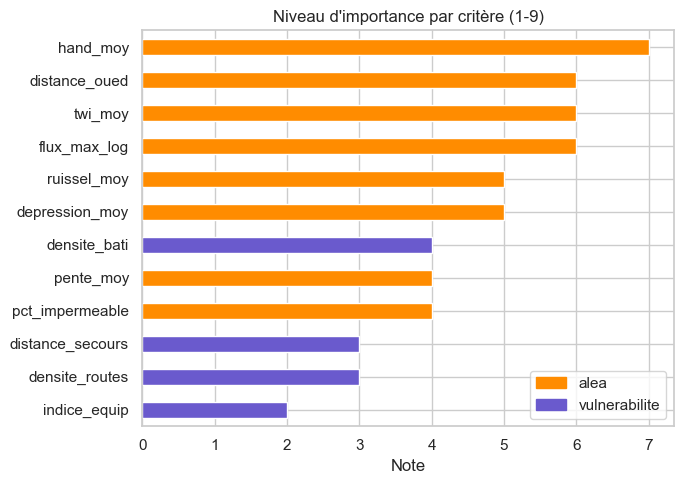

In [5]:
from matplotlib.patches import Patch
s = pd.Series(NIVEAUX).sort_values()
ax = s.plot.barh(figsize=(7, 5), color=[COULEUR_GROUPE[groupe_de[c]] for c in s.index])
ax.legend(handles=[Patch(color=v, label=k) for k, v in COULEUR_GROUPE.items()], loc="lower right")
plt.title("Niveau d'importance par critère (1-9)")
plt.xlabel("Note")
plt.tight_layout(); plt.show()

## 1 bis. Diagnostic de l'orientation (`SENS`) et des redondances
Le CSV contient des variables normalisées en min-max. Pour savoir si une valeur haute veut dire « plus de risque », on s'appuie sur la physique :
TWI et flux d'accumulation sont élevés là où l'eau s'accumule (risque haut). Si HAND, distance aux oueds ou pente sont **négativement** corrélés à TWI et au flux, ils sont bruts (valeur haute = risque bas) et doivent être inversés (`cost`).
Quand la corrélation est trop faible pour trancher, on garde le sens attendu pour des données brutes. **Vérifie le tableau avant d'utiliser les poids.**

In [6]:
df = pd.read_csv(CSV_IN)
criteres = list(NIVEAUX)                    # ordre = identifiants du diagramme (1..12)
n = len(criteres)
print("NaN dans les critères :", int(df[criteres].isna().sum().sum()))

SEUIL_RHO = 0.10
A_VERIFIER = {   # variable : (sens attendu si le CSV est en min-max BRUT, variables de référence)
    "hand_moy":       ("cost",    ["twi_moy", "flux_max_log"]),   # HAND faible près du drainage
    "distance_oued":  ("cost",    ["twi_moy", "flux_max_log"]),   # loin des oueds = moins de risque
    "pente_moy":      ("cost",    ["twi_moy"]),                   # TWI = ln(a / tan β) : forte pente = faible TWI
    "depression_moy": ("benefit", ["twi_moy", "flux_max_log"]),   # cuvettes = accumulation d'eau
}
ech = df[criteres].sample(min(len(df), 200_000), random_state=0)
ctrl = ech["twi_moy"].corr(ech["flux_max_log"], method="spearman")
print(f"Contrôle des références : rho(TWI, flux) = {ctrl:.2f}  (doit être > 0)")

SENS = {c: "benefit" for c in criteres}     # pct_impermeable, ruissel_moy, densite_*, distance_secours, indice_equip : valeur haute = risque haut
lignes = []
for v, (attendu, refs) in A_VERIFIER.items():
    rho = float(np.mean([ech[v].corr(ech[r], method="spearman") for r in refs]))
    observe = "benefit" if rho > 0 else "cost"
    fiable = (ctrl > 0.05) and (abs(rho) >= SEUIL_RHO)
    SENS[v] = observe if fiable else attendu
    lignes.append({"variable": v, "rho_moyen_refs": round(rho, 2), "sens_observe": observe,
                   "sens_attendu_brut": attendu, "fiable": fiable, "sens_retenu": SENS[v]})
for v, s in SENS_FORCE.items():
    SENS[v] = s
    print(f"SENS forcé : {v} -> {s}")

diag = pd.DataFrame(lignes).set_index("variable")
if not (diag["fiable"]).all():
    print("ATTENTION : corrélation trop faible pour au moins une variable -> sens attendu (brut) utilisé. À vérifier.")

# contrôles d'information sur la vulnérabilité (non modifiés automatiquement)
r1 = ech["distance_secours"].corr(ech["densite_bati"], method="spearman")
r2 = ech["indice_equip"].corr(ech["densite_bati"], method="spearman")
print(f"rho(distance_secours, densite_bati) = {r1:.2f}  (attendu < 0 : les secours sont en ville)")
print(f"rho(indice_equip, densite_bati)     = {r2:.2f}  (attendu > 0 : les équipements sont en ville)")
if r1 > SEUIL_RHO:
    print("-> distance_secours semble déjà inversée (proximité) : envisager SENS_FORCE = {'distance_secours': 'cost'}")
if r2 < -SEUIL_RHO:
    print("-> indice_equip semble inversé : envisager SENS_FORCE = {'indice_equip': 'cost'}")
print("Sens retenus :", {c: SENS[c] for c in criteres})
diag

NaN dans les critères : 0
Contrôle des références : rho(TWI, flux) = 0.71  (doit être > 0)
ATTENTION : corrélation trop faible pour au moins une variable -> sens attendu (brut) utilisé. À vérifier.
rho(distance_secours, densite_bati) = -0.14  (attendu < 0 : les secours sont en ville)
rho(indice_equip, densite_bati)     = 0.24  (attendu > 0 : les équipements sont en ville)
Sens retenus : {'hand_moy': 'benefit', 'flux_max_log': 'benefit', 'twi_moy': 'benefit', 'pct_impermeable': 'benefit', 'distance_oued': 'cost', 'depression_moy': 'benefit', 'ruissel_moy': 'benefit', 'pente_moy': 'benefit', 'densite_bati': 'benefit', 'densite_routes': 'benefit', 'distance_secours': 'benefit', 'indice_equip': 'benefit'}


,rho_moyen_refs,sens_observe,sens_attendu_brut,fiable,sens_retenu
variable,,,,,
hand_moy,0.50,benefit,cost,True,benefit
distance_oued,-0.04,cost,cost,False,cost
pente_moy,0.75,benefit,cost,True,benefit
depression_moy,0.53,benefit,benefit,True,benefit


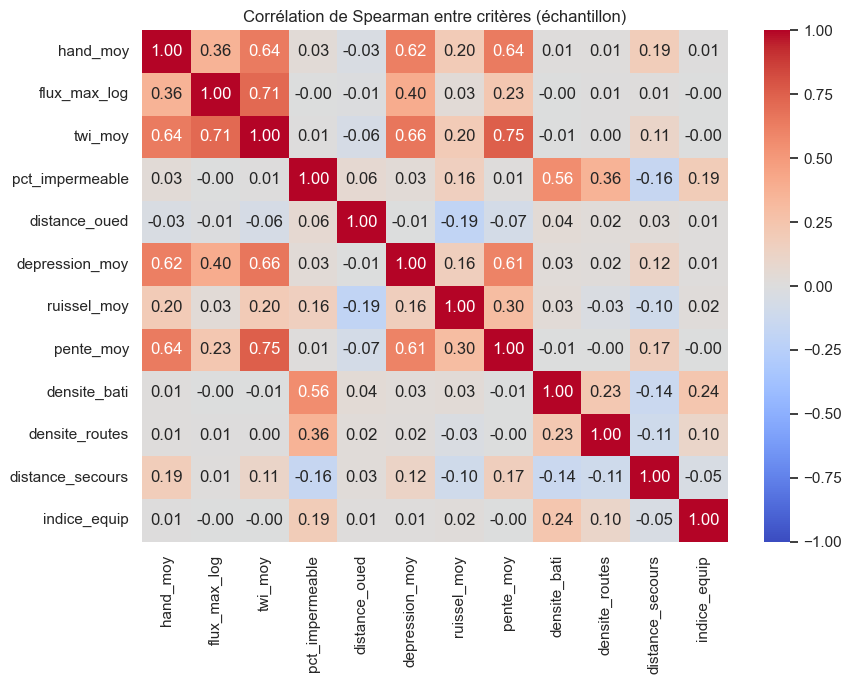

Paires très corrélées (|rho| >= 0.8) : aucune
Si une paire du même groupe est listée : fusionner ou baisser le niveau de l'un des deux critères.


In [7]:
C = ech.corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(C, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélation de Spearman entre critères (échantillon)")
plt.tight_layout(); plt.show()

paires = [(a, b, round(C.loc[a, b], 2)) for i, a in enumerate(criteres) for b in criteres[i + 1:] if abs(C.loc[a, b]) >= 0.8]
print("Paires très corrélées (|rho| >= 0.8) :", paires if paires else "aucune")
print("Si une paire du même groupe est listée : fusionner ou baisser le niveau de l'un des deux critères.")

## 2. Fonctions

In [9]:
def saaty_round(x):
    return SAATY[np.argmin(np.abs(SAATY - x))]

def matrice_saaty(criteres, niveaux=NIVEAUX):
    n = len(criteres)
    A = np.ones((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            ci, cj = criteres[i], criteres[j]
            d = niveaux[ci] - niveaux[cj]
            v = 1 + d if d >= 0 else 1 / (1 - d)
            v = saaty_round(v)
            if (ci, cj) in OVERRIDES:
                v = OVERRIDES[(ci, cj)]
            elif (cj, ci) in OVERRIDES:
                v = 1 / OVERRIDES[(cj, ci)]
            A[i, j], A[j, i] = v, 1 / v
    return A

def calculer_poids(A):
    """Vecteur propre principal + lambda_max."""
    vals, vecs = np.linalg.eig(A)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    return w / w.sum(), vals[k].real

def verifier_coherence(lambda_max, n):
    ci = (lambda_max - n) / (n - 1)
    cr = ci / RI[n] if RI[n] else 0.0
    return ci, cr

def classer(score, methode=METHODE_CLASSES):
    """5 classes (1 = très faible ... 5 = très élevé) : seuils réguliers sur le score min-max, ou quantiles."""
    if methode == "quantiles":
        return pd.qcut(score.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    s = (score - score.min()) / (score.max() - score.min())
    return pd.cut(s, [-1e-9, .2, .4, .6, .8, 1.0], labels=[1, 2, 3, 4, 5]).astype(int)

## 3. Poids et cohérence
Poids **locaux** dans chaque groupe (AHP + rapport de cohérence par groupe), poids des **groupes**, puis poids **global** = poids du groupe × poids local. La somme des poids globaux vaut 1.

In [10]:
w_loc, lam_g, ci_g, cr_g, A_g = {}, {}, {}, {}, {}
for g, cs in GROUPES.items():
    A_g[g] = matrice_saaty(cs)
    w_loc[g], lam_g[g] = calculer_poids(A_g[g])
    ci_g[g], cr_g[g] = verifier_coherence(lam_g[g], len(cs))
    print(f"[{g}] lambda_max={lam_g[g]:.4f}  CI={ci_g[g]:.4f}  CR={cr_g[g]:.4f} ->",
          "OK (CR<0.10)" if cr_g[g] < 0.10 else "INCOHÉRENT : revoir les jugements")

groupes = list(GROUPES)
A_grp = matrice_saaty(groupes, NIVEAUX_GROUPES)
w_grp, _ = calculer_poids(A_grp)
poids_groupes = pd.Series(w_grp, index=groupes)
print("Poids des groupes :", poids_groupes.round(3).to_dict())

poids = pd.Series({c: poids_groupes[g] * w_loc[g][k] for g, cs in GROUPES.items() for k, c in enumerate(cs)})
w = poids.reindex(criteres).to_numpy()                 # même ordre que `criteres`
poids = poids.sort_values(ascending=False)

g_max = max(cr_g, key=cr_g.get)                        # pire cas pour la table CalculAHP
lam, ci, cr = lam_g[g_max], ci_g[g_max], cr_g[g_max]
poids.round(4)

[alea] lambda_max=8.0492  CI=0.0070  CR=0.0050 -> OK (CR<0.10)
[vulnerabilite] lambda_max=4.0104  CI=0.0035  CR=0.0038 -> OK (CR<0.10)
Poids des groupes : {'alea': 0.833, 'vulnerabilite': 0.167}


hand_moy            0.2187
flux_max_log        0.1288
twi_moy             0.1288
distance_oued       0.1288
depression_moy      0.0719
ruissel_moy         0.0719
densite_bati        0.0706
pct_impermeable     0.0422
pente_moy           0.0422
densite_routes      0.0378
distance_secours    0.0378
indice_equip        0.0204
dtype: float64

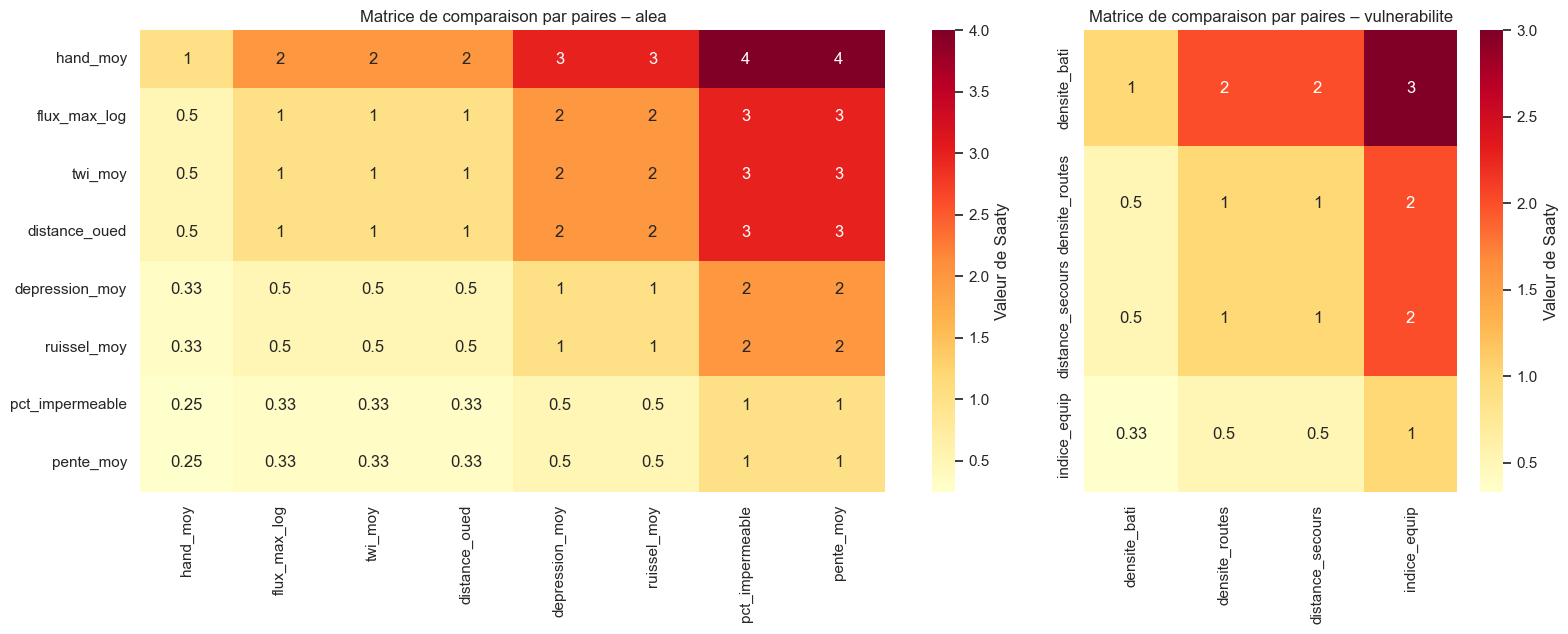

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [8, 4]})
for a, (g, cs) in zip(ax, GROUPES.items()):
    sns.heatmap(pd.DataFrame(A_g[g], index=cs, columns=cs), annot=True, fmt=".2g", cmap="YlOrRd",
                cbar_kws={"label": "Valeur de Saaty"}, ax=a)
    a.set_title(f"Matrice de comparaison par paires – {g}")
plt.tight_layout(); plt.show()

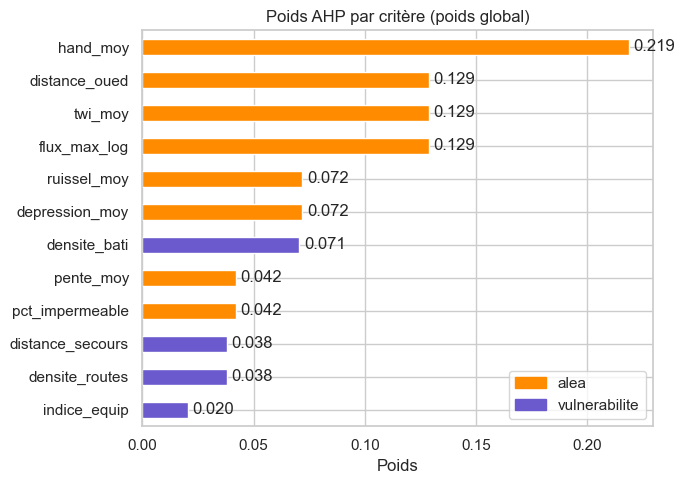

In [12]:
p = poids.sort_values()
ax = p.plot.barh(figsize=(7, 5), color=[COULEUR_GROUPE[groupe_de[c]] for c in p.index])
for i, v in enumerate(p):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
ax.legend(handles=[Patch(color=v, label=k) for k, v in COULEUR_GROUPE.items()], loc="lower right")
plt.title("Poids AHP par critère (poids global)")
plt.xlabel("Poids")
plt.tight_layout(); plt.show()

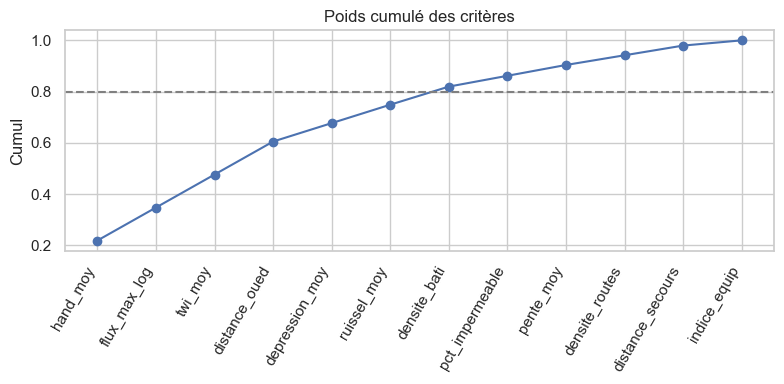

In [13]:
pc = poids.cumsum()
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pc) + 1), pc.values, marker="o")
plt.xticks(range(1, len(pc) + 1), pc.index, rotation=60, ha="right")
plt.axhline(0.8, color="gray", linestyle="--")
plt.title("Poids cumulé des critères")
plt.ylabel("Cumul")
plt.tight_layout(); plt.show()

## 4. Tables du diagramme

In [14]:
calcul = pd.DataFrame([{
    "id": CALCUL_ID, "date_calcul": datetime.now().isoformat(timespec="seconds"),
    "scenario": SCENARIO, "lambda_max": lam,
    "indice_coherence": ci, "ratio_coherence": cr,
    "cr_alea": cr_g["alea"], "cr_vulnerabilite": cr_g["vulnerabilite"]}])      # lambda/CI/CR = groupe le moins cohérent

critere = pd.DataFrame({"id": range(1, n + 1), "calcul_id": CALCUL_ID,
                        "variable": criteres, "sens": [SENS[c] for c in criteres],
                        "poids": w, "groupe": [groupe_de[c] for c in criteres]})

idx = {c: k + 1 for k, c in enumerate(criteres)}
comparaison = pd.DataFrame([{"calcul_id": CALCUL_ID, "critere_i": idx[cs[i]], "critere_j": idx[cs[j]],
                             "valeur_saaty": A_g[g][i, j], "groupe": g}
                            for g, cs in GROUPES.items()
                            for i in range(len(cs)) for j in range(i + 1, len(cs))])

calcul.to_csv(OUT / "calcul_ahp.csv", index=False)
critere.to_csv(OUT / "critere_ahp.csv", index=False)
comparaison.to_csv(OUT / "comparaison_paire.csv", index=False)
critere

,id,calcul_id,variable,sens,poids,groupe
0,1,1,hand_moy,benefit,0.218731,alea
1,2,1,flux_max_log,benefit,0.128788,alea
2,3,1,twi_moy,benefit,0.128788,alea
3,4,1,pct_impermeable,benefit,0.042216,alea
4,5,1,distance_oued,cost,0.128788,alea
5,6,1,depression_moy,benefit,0.071903,alea
6,7,1,ruissel_moy,benefit,0.071903,alea
7,8,1,pente_moy,benefit,0.042216,alea
8,9,1,densite_bati,benefit,0.070598,vulnerabilite
9,10,1,densite_routes,benefit,0.037841,vulnerabilite


## 5. Score de risque par maille (`ScoreRisque.calculer()`)

In [15]:
X = df[criteres].to_numpy(dtype="float32")
sgn = np.array([1 if SENS[c] == "benefit" else -1 for c in criteres])
X = np.where(sgn > 0, X, 1 - X)                          # toutes les variables orientées : valeur haute = risque haut
valeur = X @ w.astype("float32")

col = {c: k for k, c in enumerate(criteres)}
def sous_score(g):
    return X[:, [col[c] for c in GROUPES[g]]] @ w_loc[g].astype("float32")
score_alea, score_vuln = sous_score("alea"), sous_score("vulnerabilite")
assert np.allclose(valeur, poids_groupes["alea"] * score_alea + poids_groupes["vulnerabilite"] * score_vuln, atol=1e-4)

score = pd.DataFrame({"maille_id": df["id"], "calcul_id": CALCUL_ID,
                      "valeur": valeur, "classe": classer(pd.Series(valeur)),
                      "score_alea": score_alea, "score_vulnerabilite": score_vuln})
score.to_csv(OUT / "score_risque.csv", index=False)
print((100 * score["classe"].value_counts(normalize=True).sort_index()).round(2).to_dict(), "(% de mailles par classe)")
score["classe"].value_counts().sort_index()

{1: 0.19, 2: 14.06, 3: 75.61, 4: 10.06, 5: 0.08} (% de mailles par classe)


classe
1       3917
2     284180
3    1527775
4     203252
5       1581
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(score["valeur"], bins=100, color="teal")
plt.title("Distribution du score de risque")
plt.xlabel("Score"); plt.ylabel("Nombre de mailles")
plt.yscale("log")
plt.tight_layout(); plt.show()

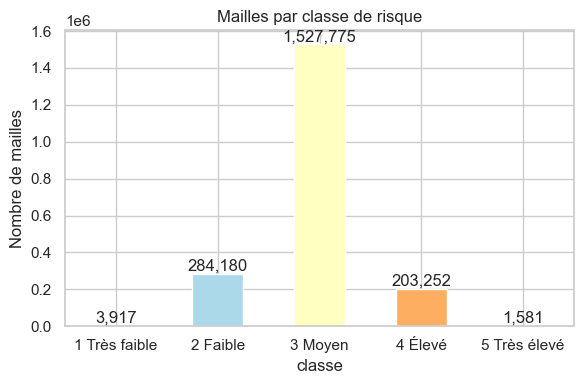

In [16]:
couleurs = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
cl = score["classe"].value_counts().sort_index().reindex([1, 2, 3, 4, 5], fill_value=0)
ax = cl.plot.bar(color=couleurs, figsize=(6, 4))
for i, v in enumerate(cl):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_xticklabels(["1 Très faible", "2 Faible", "3 Moyen", "4 Élevé", "5 Très élevé"], rotation=0)
plt.title("Mailles par classe de risque")
plt.ylabel("Nombre de mailles")
plt.tight_layout(); plt.show()

In [17]:
import geopandas as gpd
import pyogrio
from matplotlib.colors import ListedColormap

fichier = DOSSIER_MAILLES / "mailles_100m.gpkg"

# 1. voir les couches et leurs colonnes
for couche in pyogrio.list_layers(fichier)[:, 0]:
    g = gpd.read_file(fichier, layer=couche, rows=2)
    print(couche, "->", list(g.columns))

mailles_100m -> ['maille_id', 'surface_m2', 'centroide_x', 'centroide_y', 'commune_id', 'geometry']
maille_centroide -> ['id', 'geometry']
maille -> ['id', 'centroide', 'taille_m', 'commune_id', 'geometry']


2020705 mailles jointes sur 2020705


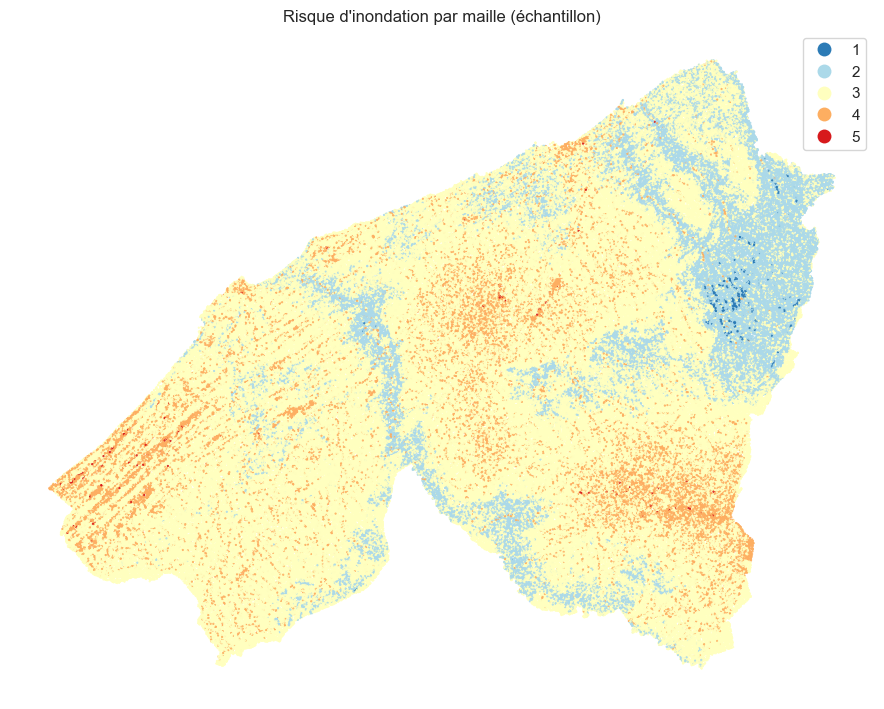

In [18]:
couleurs = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]

pts = gpd.read_file(fichier, layer="maille_centroide", fid_as_index=True)

# trouver la colonne identifiant
candidats = [c for c in ["id", "maille_id", "id_maille", "ID", "fid"] if c in pts.columns]
if candidats:
    pts = pts.rename(columns={candidats[0]: "maille_id"})
else:
    pts["maille_id"] = pts.index      # sinon on utilise le fid du GPKG
    print("Aucune colonne id : jointure par fid. Vérifie que la carte est cohérente.")

pts = pts[["maille_id", "geometry"]].merge(
    score[["maille_id", "classe"]], on="maille_id")
print(len(pts), "mailles jointes sur", len(score))

pts = pts.sample(min(300_000, len(pts)), random_state=0)

fig, ax = plt.subplots(figsize=(9, 9))
pts.plot(column="classe", cmap=ListedColormap(couleurs), markersize=0.3,
         legend=True, categorical=True, ax=ax)
ax.set_title("Risque d'inondation par maille (échantillon)")
ax.set_axis_off()
plt.tight_layout(); plt.show()